In [1]:
"""
WESAD Binary Stress Detection - Notebook 4: Model Evaluation
=============================================================
STRICT COMPLIANCE: Evaluation metrics are MANDATORY as specified.
"""

# ============================================================================
# FIXED CONFIGURATION - DO NOT MODIFY
# ============================================================================

EVAL_CONFIG = {
    # Mandatory Evaluation Metrics (FIXED)
    'required_metrics': [
        'accuracy',      # FIXED: MANDATORY
        'precision',     # FIXED: MANDATORY
        'recall',        # FIXED: MANDATORY
        'f1_score',      # FIXED: MANDATORY
        'roc_auc',       # FIXED: MANDATORY
    ],
    
    # Model paths
    'best_model_path': 'models/best_model_checkpoint.h5',  # STEP 4.3: Load best validation checkpoint
    'final_model_path': 'models/late_fusion_cnn_lstm_model.h5',
    'history_path': 'models/training_history.pkl',
    'split_info_path': 'models/split_info.pkl',
}

In [2]:
# ============================================================================
# IMPORTS
# ============================================================================

import numpy as np
import pickle
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

import warnings
warnings.filterwarnings('ignore')

print(f"TensorFlow version: {tf.__version__}")

TensorFlow version: 2.20.0


In [3]:
# ============================================================================
# LOAD MODEL AND DATA
# ============================================================================

def load_best_model(model_path='models/best_model_checkpoint.h5'):
    """
    STEP 4.3: Load the best validation checkpoint
    """
    if not Path(model_path).exists():
        print(f"Warning: Best checkpoint not found at {model_path}")
        print("Falling back to final model...")
        model_path = 'models/late_fusion_cnn_lstm_model.h5'
    
    model = keras.models.load_model(model_path)
    print(f"Model loaded from: {model_path}")
    return model

def load_training_history(history_path='models/training_history.pkl'):
    """Load training history."""
    with open(history_path, 'rb') as f:
        history = pickle.load(f)
    print(f"History loaded from: {history_path}")
    return history

def load_split_info(split_info_path='models/split_info.pkl'):
    """Load train/val/test split information."""
    with open(split_info_path, 'rb') as f:
        split_info = pickle.load(f)
    print(f"Split info loaded from: {split_info_path}")
    return split_info

def load_preprocessed_data(input_file='processed_data/preprocessed_windowed_data.pkl'):
    """Load preprocessed data."""
    with open(input_file, 'rb') as f:
        saved_data = pickle.load(f)
    return saved_data['data'], saved_data['config']

In [4]:
# ============================================================================
# DATA PREPARATION (REUSE FROM NOTEBOOK 3)
# ============================================================================

def organize_data_by_modality(preprocessed_data):
    """Organize windowed data by modality."""
    modality_data = {
        'ECG': [], 'EDA': [], 'EMG': [], 'Respiration': [], 'Temperature': []
    }
    subject_labels = {}
    
    for subject_id, subject_data in preprocessed_data.items():
        signals = subject_data['signals']
        labels = subject_data['labels']
        
        subject_labels[subject_id] = labels
        
        for modality in modality_data.keys():
            modality_windows = signals[modality]
            modality_data[modality].append((subject_id, modality_windows))
    
    return modality_data, subject_labels

def split_data_by_subjects(modality_data, subject_labels, train_subjects, val_subjects, test_subjects):
    """Split data according to subject-independent strategy."""
    modalities = ['ECG', 'EDA', 'EMG', 'Respiration', 'Temperature']
    
    splits = {
        'train': {modality: [] for modality in modalities},
        'val': {modality: [] for modality in modalities},
        'test': {modality: [] for modality in modalities},
    }
    
    labels_split = {'train': [], 'val': [], 'test': []}
    
    split_assignment = {}
    for subject_id in train_subjects:
        split_assignment[subject_id] = 'train'
    for subject_id in val_subjects:
        split_assignment[subject_id] = 'val'
    for subject_id in test_subjects:
        split_assignment[subject_id] = 'test'
    
    for modality in modalities:
        for subject_id, modality_windows in modality_data[modality]:
            if subject_id in split_assignment:
                split_type = split_assignment[subject_id]
                splits[split_type][modality].append(modality_windows)
                
                if modality == modalities[0]:
                    labels_split[split_type].append(subject_labels[subject_id])
    
    for split_type in ['train', 'val', 'test']:
        for modality in modalities:
            if splits[split_type][modality]:
                splits[split_type][modality] = np.concatenate(splits[split_type][modality], axis=0)
            else:
                splits[split_type][modality] = np.array([])
        
        if labels_split[split_type]:
            labels_split[split_type] = np.concatenate(labels_split[split_type], axis=0)
        else:
            labels_split[split_type] = np.array([])
    
    return splits, labels_split

def prepare_model_inputs(data_splits, modalities):
    """Prepare input data for multi-input model."""
    inputs = []
    for modality in modalities:
        modality_data = data_splits[modality]
        modality_data = modality_data.reshape(-1, 240, 1)
        inputs.append(modality_data)
    
    return inputs

In [5]:
# ============================================================================
# EVALUATION METRICS (MANDATORY)
# ============================================================================

def calculate_metrics(y_true, y_pred, y_pred_proba):
    """
    Calculate all MANDATORY evaluation metrics.
    
    FIXED METRICS:
    - Accuracy: (TP + TN) / (TP + TN + FP + FN)
    - Precision
    - Recall
    - F1-score
    - ROC-AUC
    
    Args:
        y_true: True labels
        y_pred: Predicted labels (binary)
        y_pred_proba: Predicted probabilities
        
    Returns:
        Dictionary of metrics
    """
    metrics = {}
    
    # Accuracy (MANDATORY)
    metrics['accuracy'] = accuracy_score(y_true, y_pred)
    
    # Precision (MANDATORY)
    metrics['precision'] = precision_score(y_true, y_pred, zero_division=0)
    
    # Recall (MANDATORY)
    metrics['recall'] = recall_score(y_true, y_pred, zero_division=0)
    
    # F1-score (MANDATORY)
    metrics['f1_score'] = f1_score(y_true, y_pred, zero_division=0)
    
    # ROC-AUC (MANDATORY)
    metrics['roc_auc'] = roc_auc_score(y_true, y_pred_proba)
    
    return metrics

def print_metrics(metrics, split_name="Test"):
    """Print evaluation metrics in formatted manner."""
    print(f"\n{'='*60}")
    print(f"{split_name} Set - Evaluation Metrics (MANDATORY)")
    print(f"{'='*60}")
    print(f"Accuracy:   {metrics['accuracy']:.4f}")
    print(f"Precision:  {metrics['precision']:.4f}")
    print(f"Recall:     {metrics['recall']:.4f}")
    print(f"F1-Score:   {metrics['f1_score']:.4f}")
    print(f"ROC-AUC:    {metrics['roc_auc']:.4f}")
    print(f"{'='*60}")

In [6]:
# ============================================================================
# VISUALIZATION - TRAINING HISTORY
# ============================================================================

def plot_training_history(history):
    """
    Plot and save training history (STEP 4.4).
    """
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    epochs = range(1, len(history['loss']) + 1)
    
    # Loss
    axes[0].plot(epochs, history['loss'], 'b-', label='Training Loss', linewidth=2, marker='o', markersize=4)
    axes[0].plot(epochs, history['val_loss'], 'r-', label='Validation Loss', linewidth=2, marker='s', markersize=4)
    axes[0].set_xlabel('Epoch', fontsize=12)
    axes[0].set_ylabel('Loss', fontsize=12)
    axes[0].set_title('Training vs Validation Loss', fontsize=14, fontweight='bold')
    axes[0].legend(fontsize=11)
    axes[0].grid(True, alpha=0.3)
    
    # Accuracy
    axes[1].plot(epochs, history['accuracy'], 'b-', label='Training Accuracy', linewidth=2, marker='o', markersize=4)
    axes[1].plot(epochs, history['val_accuracy'], 'r-', label='Validation Accuracy', linewidth=2, marker='s', markersize=4)
    axes[1].set_xlabel('Epoch', fontsize=12)
    axes[1].set_ylabel('Accuracy', fontsize=12)
    axes[1].set_title('Training vs Validation Accuracy', fontsize=14, fontweight='bold')
    axes[1].legend(fontsize=11)
    axes[1].grid(True, alpha=0.3)
    axes[1].set_ylim([0, 1.05])
    
    plt.tight_layout()
    
    # Save to disk (STEP 4.4 requirement)
    save_path = 'results/training_history.png'
    output_path = Path(save_path).parent
    output_path.mkdir(exist_ok=True)
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"✓ Training curves saved to: {save_path}")
    
    plt.show()
    
    # Print training statistics
    print("\n" + "="*70)
    print("TRAINING STATISTICS")
    print("="*70)
    print(f"Total epochs run: {len(epochs)}")
    print(f"\nFinal Training Loss:      {history['loss'][-1]:.4f}")
    print(f"Final Validation Loss:    {history['val_loss'][-1]:.4f}")
    print(f"Final Training Accuracy:  {history['accuracy'][-1]:.4f}")
    print(f"Final Validation Accuracy: {history['val_accuracy'][-1]:.4f}")
    
    print(f"\nBest Validation Loss:     {min(history['val_loss']):.4f} (Epoch {np.argmin(history['val_loss'])+1})")
    print(f"Best Validation Accuracy: {max(history['val_accuracy']):.4f} (Epoch {np.argmax(history['val_accuracy'])+1})")
    
    # Overfitting check
    final_gap = history['accuracy'][-1] - history['val_accuracy'][-1]
    print(f"\nFinal Train-Val Accuracy Gap: {final_gap:.4f}")
    if final_gap < 0.03:
        print("  ✓ Minimal overfitting detected")
    elif final_gap < 0.05:
        print("  ⚠ Slight overfitting detected")
    else:
        print("  ⚠ Moderate overfitting detected")
    print("="*70)

In [7]:
# ============================================================================
# CONFUSION MATRIX
# ============================================================================

def plot_confusion_matrix(y_true, y_pred, title="Confusion Matrix", save_path='results/confusion_matrix.png'):
    """
    Plot and save confusion matrix (STEP 4.4).
    """
    cm = confusion_matrix(y_true, y_pred)
    
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
                xticklabels=['Non-Stress', 'Stress'],
                yticklabels=['Non-Stress', 'Stress'],
                annot_kws={'size': 14})
    plt.title(title, fontsize=16, fontweight='bold')
    plt.ylabel('True Label', fontsize=13)
    plt.xlabel('Predicted Label', fontsize=13)
    plt.tight_layout()
    
    # Save to disk (STEP 4.4 requirement)
    output_path = Path(save_path).parent
    output_path.mkdir(exist_ok=True)
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"✓ Confusion matrix saved to: {save_path}")
    
    plt.show()
    
    return cm

In [8]:
# ============================================================================
# ROC CURVE
# ============================================================================

def plot_roc_curve(y_true, y_pred_proba, title="ROC Curve", save_path='results/roc_curve.png'):
    """
    Plot and save ROC curve (STEP 4.4).
    """
    fpr, tpr, thresholds = roc_curve(y_true, y_pred_proba)
    auc = roc_auc_score(y_true, y_pred_proba)
    
    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, linewidth=2.5, label=f'ROC Curve (AUC = {auc:.4f})', color='#2E86AB')
    plt.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Random Classifier', alpha=0.5)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate', fontsize=13)
    plt.ylabel('True Positive Rate', fontsize=13)
    plt.title(title, fontsize=16, fontweight='bold')
    plt.legend(loc='lower right', fontsize=12)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    
    # Save to disk (STEP 4.4 requirement)
    output_path = Path(save_path).parent
    output_path.mkdir(exist_ok=True)
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"✓ ROC curve saved to: {save_path}")
    
    plt.show()

In [9]:
# ============================================================================
# CLASSIFICATION REPORT
# ============================================================================

def print_classification_report(y_true, y_pred):
    """Print detailed classification report."""
    print("\nDetailed Classification Report:")
    print("="*60)
    report = classification_report(
        y_true, y_pred,
        target_names=['Non-Stress', 'Stress'],
        digits=4
    )
    print(report)

# ============================================================================
# PER-SUBJECT ANALYSIS
# ============================================================================

def evaluate_per_subject(model, preprocessed_data, test_subjects):
    """
    Evaluate model performance on each test subject individually.
    
    Returns:
        Dictionary of per-subject metrics
    """
    print("\n" + "="*70)
    print("PER-SUBJECT ANALYSIS (Test Set)")
    print("="*70)
    
    modality_data, subject_labels = organize_data_by_modality(preprocessed_data)
    modalities = ['ECG', 'EDA', 'EMG', 'Respiration', 'Temperature']
    
    subject_results = {}
    
    for subject_id in test_subjects:
        if subject_id not in preprocessed_data:
            print(f"\nSkipping {subject_id} (not found in data)")
            continue
            
        print(f"\nEvaluating {subject_id}...")
        
        # Get subject data
        subject_data = preprocessed_data[subject_id]
        signals = subject_data['signals']
        labels = subject_data['labels']
        
        # Prepare inputs
        inputs = []
        for modality in modalities:
            modality_data = signals[modality].reshape(-1, 240, 1)
            inputs.append(modality_data)
        
        # Predict
        y_pred_proba = model.predict(inputs, verbose=0).flatten()
        y_pred = (y_pred_proba > 0.5).astype(int)
        
        # Calculate metrics
        metrics = calculate_metrics(labels, y_pred, y_pred_proba)
        subject_results[subject_id] = metrics
        
        print(f"  Windows: {len(labels)}")
        print(f"  Accuracy: {metrics['accuracy']:.4f}")
        print(f"  F1-Score: {metrics['f1_score']:.4f}")
        print(f"  ROC-AUC: {metrics['roc_auc']:.4f}")
    
    return subject_results

def summarize_per_subject_results(subject_results):
    """Summarize per-subject evaluation results."""
    print("\n" + "="*70)
    print("PER-SUBJECT SUMMARY (Test Set)")
    print("="*70)
    
    # Collect metrics
    all_metrics = {
        'accuracy': [],
        'precision': [],
        'recall': [],
        'f1_score': [],
        'roc_auc': []
    }
    
    print(f"\n{'Subject':<10} {'Accuracy':<10} {'Precision':<10} {'Recall':<10} {'F1-Score':<10} {'ROC-AUC':<10}")
    print("-" * 70)
    
    for subject_id, metrics in subject_results.items():
        print(f"{subject_id:<10} {metrics['accuracy']:<10.4f} {metrics['precision']:<10.4f} "
              f"{metrics['recall']:<10.4f} {metrics['f1_score']:<10.4f} {metrics['roc_auc']:<10.4f}")
        
        for metric_name in all_metrics.keys():
            all_metrics[metric_name].append(metrics[metric_name])
    
    print("-" * 70)
    
    # Print average
    if all_metrics['accuracy']:
        print(f"{'Average':<10} {np.mean(all_metrics['accuracy']):<10.4f} "
              f"{np.mean(all_metrics['precision']):<10.4f} {np.mean(all_metrics['recall']):<10.4f} "
              f"{np.mean(all_metrics['f1_score']):<10.4f} {np.mean(all_metrics['roc_auc']):<10.4f}")
        print(f"{'Std Dev':<10} {np.std(all_metrics['accuracy']):<10.4f} "
              f"{np.std(all_metrics['precision']):<10.4f} {np.std(all_metrics['recall']):<10.4f} "
              f"{np.std(all_metrics['f1_score']):<10.4f} {np.std(all_metrics['roc_auc']):<10.4f}")
    
    print("="*70)
    
    return all_metrics

def plot_per_subject_metrics(subject_results):
    """Visualize per-subject metrics."""
    if not subject_results:
        print("No subject results to plot")
        return
        
    subjects = list(subject_results.keys())
    metrics_names = ['accuracy', 'precision', 'recall', 'f1_score', 'roc_auc']  # is this enough??
    
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    fig.suptitle('Per-Subject Metrics (Test Set)', fontsize=16)
    axes = axes.flatten()
    
    for idx, metric_name in enumerate(metrics_names):
        values = [subject_results[s][metric_name] for s in subjects]
        
        axes[idx].bar(range(len(subjects)), values, alpha=0.7, color='steelblue')
        axes[idx].axhline(y=np.mean(values), color='r', linestyle='--', 
                         linewidth=2, label=f'Mean: {np.mean(values):.3f}')
        axes[idx].set_xticks(range(len(subjects)))
        axes[idx].set_xticklabels(subjects, rotation=45, ha='right')
        axes[idx].set_ylabel(metric_name.capitalize())
        axes[idx].set_title(f'{metric_name.capitalize()} per Subject')
        axes[idx].legend()
        axes[idx].grid(True, alpha=0.3, axis='y')
        axes[idx].set_ylim([0, 1.05])
    
    # Remove extra subplot
    fig.delaxes(axes[5])
    
    plt.tight_layout()
    plt.show()

WESAD BINARY STRESS DETECTION - NOTEBOOK 4: EVALUATION
STEP 4.3 — TEST SET EVALUATION (ONCE ONLY)

⚠ CRITICAL: Test set should only be evaluated ONCE
⚠ No retraining or tuning after seeing test results

[1/9] Loading best validation checkpoint...


Model loaded from: models/best_model_checkpoint.h5

[2/9] Loading training history...
History loaded from: models/training_history.pkl

[3/9] Loading split information...
Split info loaded from: models/split_info.pkl

Data splits used during training:
  Train subjects (10): ['S11', 'S14', 'S2', 'S16', 'S7', 'S10', 'S4', 'S3', 'S17', 'S6']
  Val subjects (2): ['S9', 'S13']
  Test subjects (3): ['S15', 'S5', 'S8']

[4/9] Analyzing training history...
✓ Training curves saved to: results/training_history.png


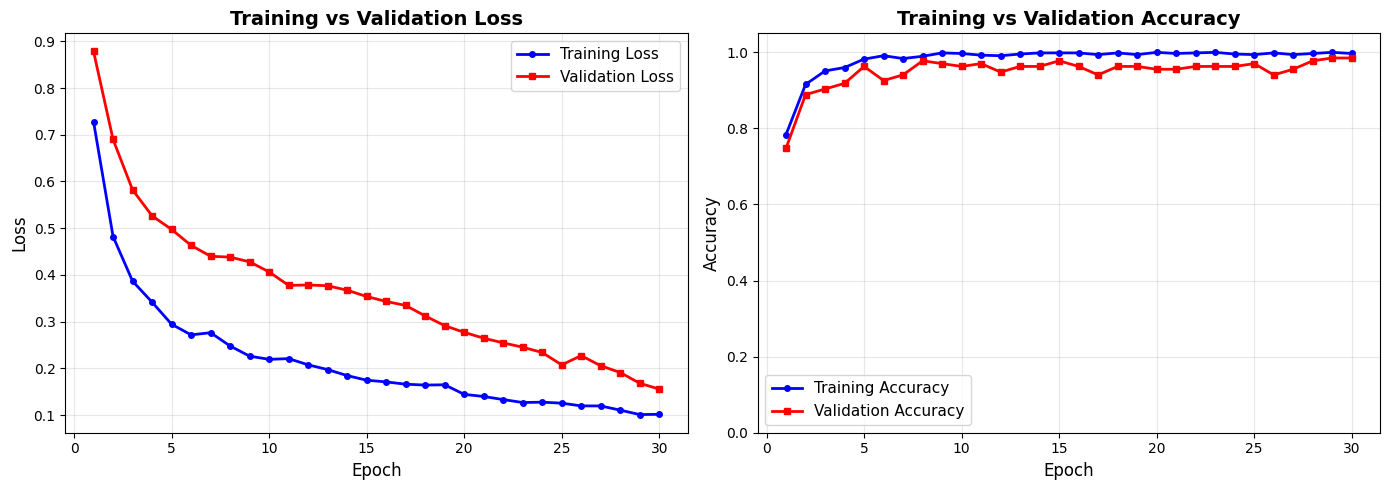


TRAINING STATISTICS
Total epochs run: 30

Final Training Loss:      0.1017
Final Validation Loss:    0.1557
Final Training Accuracy:  0.9970
Final Validation Accuracy: 0.9852

Best Validation Loss:     0.1557 (Epoch 30)
Best Validation Accuracy: 0.9852 (Epoch 29)

Final Train-Val Accuracy Gap: 0.0119
  ✓ Minimal overfitting detected

[5/9] Loading preprocessed data...

[6/9] Preparing test data (held-out subjects)...

Test set composition:
  Test subjects: ['S15', 'S5', 'S8']
  Total test samples: 204
  Stress samples: 61 (29.9%)
  Non-Stress samples: 143 (70.1%)

[7/9] Evaluating on held-out test set (ONCE ONLY)...
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 197ms/step

Test Set - Evaluation Metrics (MANDATORY)
Accuracy:   0.9363
Precision:  1.0000
Recall:     0.7869
F1-Score:   0.8807
ROC-AUC:    0.9729

[8/9] Generating and saving visualizations...

Confusion Matrix:
✓ Confusion matrix saved to: results/confusion_matrix.png


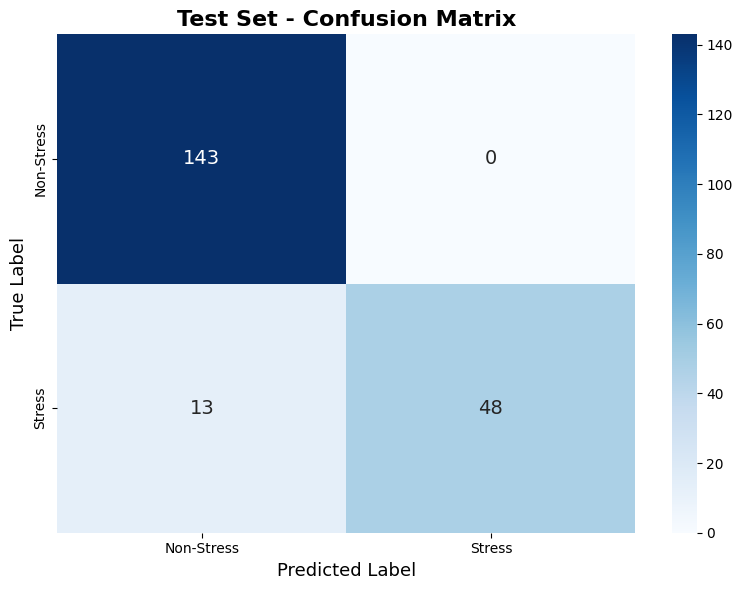


ROC Curve:
✓ ROC curve saved to: results/roc_curve.png


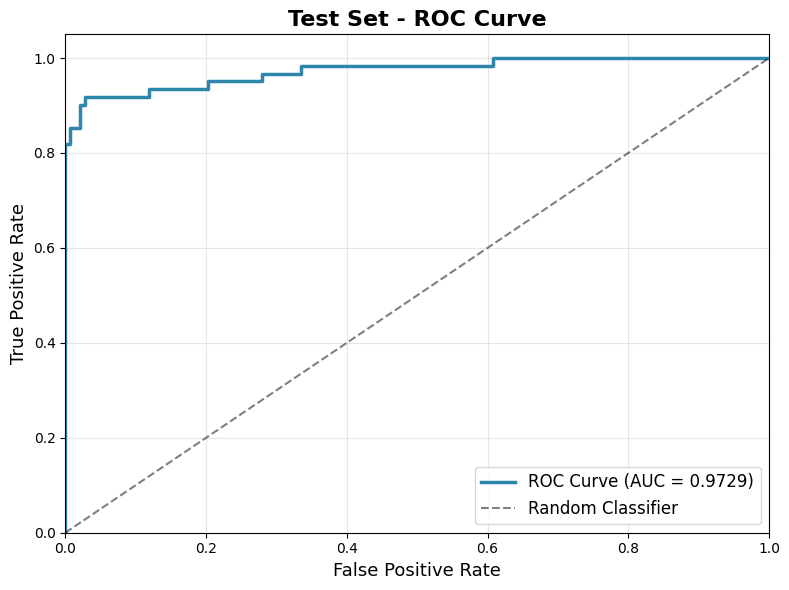


Detailed Classification Report:
              precision    recall  f1-score   support

  Non-Stress     0.9167    1.0000    0.9565       143
      Stress     1.0000    0.7869    0.8807        61

    accuracy                         0.9363       204
   macro avg     0.9583    0.8934    0.9186       204
weighted avg     0.9416    0.9363    0.9339       204


[9/9] Per-subject analysis on test set...

PER-SUBJECT ANALYSIS (Test Set)

Evaluating S15...
  Windows: 69
  Accuracy: 0.9855
  F1-Score: 0.9756
  ROC-AUC: 1.0000

Evaluating S5...
  Windows: 67
  Accuracy: 0.9254
  F1-Score: 0.8485
  ROC-AUC: 0.9572

Evaluating S8...
  Windows: 68
  Accuracy: 0.8971
  F1-Score: 0.8000
  ROC-AUC: 0.9666

PER-SUBJECT SUMMARY (Test Set)

Subject    Accuracy   Precision  Recall     F1-Score   ROC-AUC   
----------------------------------------------------------------------
S15        0.9855     1.0000     0.9524     0.9756     1.0000    
S5         0.9254     1.0000     0.7368     0.8485     0.9572  

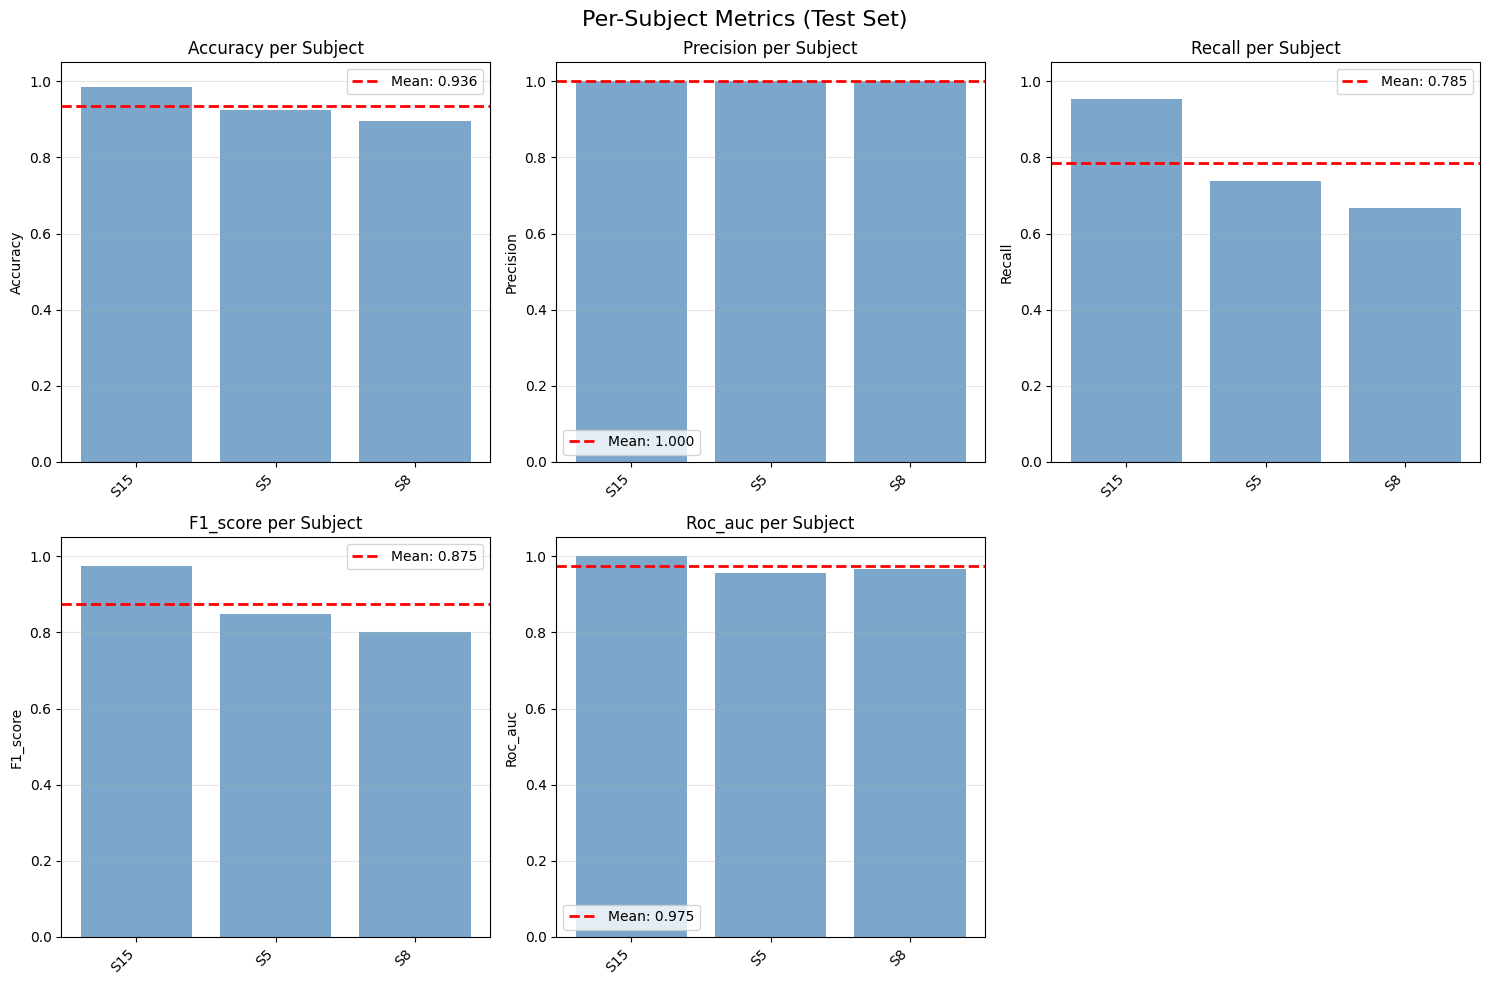


[10/10] Saving evaluation results...

Evaluation results saved to: results\evaluation_results.pkl

✓ STEP 4.3 COMPLETE - TEST SET EVALUATED (ONCE ONLY)

PROJECT COMPLETE - WESAD BINARY STRESS DETECTION

📊 FINAL TEST SET PERFORMANCE (Held-Out Subjects):
  Accuracy:   0.9363
  Precision:  1.0000
  Recall:     0.7869
  F1-Score:   0.8807
  ROC-AUC:    0.9729

📊 PER-SUBJECT STATISTICS (n=3 test subjects):
  Accuracy:   0.9360 ± 0.0369
  F1-Score:   0.8747 ± 0.0740
  ROC-AUC:    0.9746 ± 0.0184

⚠ REMINDER: No further tuning or retraining permitted
All plots saved to results/ directory for report


In [10]:
# ============================================================================
# SAVE EVALUATION RESULTS
# ============================================================================

def save_evaluation_results(test_metrics, subject_results=None, output_dir='results'):
    """Save evaluation results."""
    output_path = Path(output_dir)
    output_path.mkdir(exist_ok=True)
    
    # Save metrics
    results = {
        'test_metrics': test_metrics,
        'subject_results': subject_results
    }
    
    output_file = output_path / 'evaluation_results.pkl'
    with open(output_file, 'wb') as f:
        pickle.dump(results, f)
    
    print(f"\nEvaluation results saved to: {output_file}")

# ============================================================================
# MAIN EXECUTION
# ============================================================================

if __name__ == "__main__":
    print("="*70)
    print("WESAD BINARY STRESS DETECTION - NOTEBOOK 4: EVALUATION")
    print("STEP 4.3 — TEST SET EVALUATION (ONCE ONLY)")
    print("="*70)
    print("\n⚠ CRITICAL: Test set should only be evaluated ONCE")
    print("⚠ No retraining or tuning after seeing test results")
    print("="*70)
    
    # Step 1: Load best validation checkpoint (STEP 4.3)
    print("\n[1/9] Loading best validation checkpoint...")
    model = load_best_model(EVAL_CONFIG['best_model_path'])
    
    # Step 2: Load training history
    print("\n[2/9] Loading training history...")
    history = load_training_history(EVAL_CONFIG['history_path'])
    
    # Step 3: Load split information
    print("\n[3/9] Loading split information...")
    split_info = load_split_info(EVAL_CONFIG['split_info_path'])
    train_subjects = split_info['train_subjects']
    val_subjects = split_info['val_subjects']
    test_subjects = split_info['test_subjects']
    
    print(f"\nData splits used during training:")
    print(f"  Train subjects ({len(train_subjects)}): {train_subjects}")
    print(f"  Val subjects ({len(val_subjects)}): {val_subjects}")
    print(f"  Test subjects ({len(test_subjects)}): {test_subjects}")
    
    # Step 4: Visualize training history (STEP 4.4)
    print("\n[4/9] Analyzing training history...")
    plot_training_history(history)
    
    # Step 5: Load preprocessed data
    print("\n[5/9] Loading preprocessed data...")
    preprocessed_data, preprocess_config = load_preprocessed_data()
    
    # Step 6: Prepare test data
    print("\n[6/9] Preparing test data (held-out subjects)...")
    subject_ids = list(preprocessed_data.keys())
    modality_data, subject_labels = organize_data_by_modality(preprocessed_data)
    
    splits, labels_split = split_data_by_subjects(
        modality_data, subject_labels, train_subjects, val_subjects, test_subjects
    )
    
    modalities = ['ECG', 'EDA', 'EMG', 'Respiration', 'Temperature']
    test_inputs = prepare_model_inputs(splits['test'], modalities)
    test_labels = labels_split['test']
    
    print(f"\nTest set composition:")
    print(f"  Test subjects: {test_subjects}")
    print(f"  Total test samples: {len(test_labels)}")
    print(f"  Stress samples: {np.sum(test_labels==1)} ({np.sum(test_labels==1)/len(test_labels)*100:.1f}%)")
    print(f"  Non-Stress samples: {np.sum(test_labels==0)} ({np.sum(test_labels==0)/len(test_labels)*100:.1f}%)")
    
    # Step 7: Evaluate on test set (STEP 4.3 - ONCE ONLY)
    print("\n[7/9] Evaluating on held-out test set (ONCE ONLY)...")
    print("="*70)
    y_pred_proba = model.predict(test_inputs, verbose=1).flatten()
    y_pred = (y_pred_proba > 0.5).astype(int)
    
    # Calculate MANDATORY metrics (STEP 4.3)
    test_metrics = calculate_metrics(test_labels, y_pred, y_pred_proba)
    print_metrics(test_metrics, split_name="Test")
    
    # Step 8: Generate visualizations (STEP 4.4)
    print("\n[8/9] Generating and saving visualizations...")
    
    # Confusion matrix (STEP 4.4)
    print("\nConfusion Matrix:")
    cm = plot_confusion_matrix(test_labels, y_pred, 
                               title="Test Set - Confusion Matrix",
                               save_path='results/confusion_matrix.png')
    
    # ROC curve (STEP 4.4)
    print("\nROC Curve:")
    plot_roc_curve(test_labels, y_pred_proba, 
                   title="Test Set - ROC Curve",
                   save_path='results/roc_curve.png')
    
    # Classification report
    print_classification_report(test_labels, y_pred)
    
    # Step 9: Per-subject analysis
    print("\n[9/9] Per-subject analysis on test set...")
    subject_results = evaluate_per_subject(model, preprocessed_data, test_subjects)
    
    if subject_results:
        all_metrics = summarize_per_subject_results(subject_results)
        plot_per_subject_metrics(subject_results)
    
    # Save results
    print("\n[10/10] Saving evaluation results...")
    save_evaluation_results(test_metrics, subject_results)
    
    print("\n" + "="*70)
    print("✓ STEP 4.3 COMPLETE - TEST SET EVALUATED (ONCE ONLY)")
    print("="*70)
    
    print("\n" + "="*70)
    print("PROJECT COMPLETE - WESAD BINARY STRESS DETECTION")
    print("="*70)
    
    print("\n📊 FINAL TEST SET PERFORMANCE (Held-Out Subjects):")
    print("="*70)
    print(f"  Accuracy:   {test_metrics['accuracy']:.4f}")
    print(f"  Precision:  {test_metrics['precision']:.4f}")
    print(f"  Recall:     {test_metrics['recall']:.4f}")
    print(f"  F1-Score:   {test_metrics['f1_score']:.4f}")
    print(f"  ROC-AUC:    {test_metrics['roc_auc']:.4f}")
    
    if subject_results:
        print(f"\n📊 PER-SUBJECT STATISTICS (n={len(subject_results)} test subjects):")
        print("="*70)
        print(f"  Accuracy:   {np.mean([m['accuracy'] for m in subject_results.values()]):.4f} ± {np.std([m['accuracy'] for m in subject_results.values()]):.4f}")
        print(f"  F1-Score:   {np.mean([m['f1_score'] for m in subject_results.values()]):.4f} ± {np.std([m['f1_score'] for m in subject_results.values()]):.4f}")
        print(f"  ROC-AUC:    {np.mean([m['roc_auc'] for m in subject_results.values()]):.4f} ± {np.std([m['roc_auc'] for m in subject_results.values()]):.4f}")
    
    print("\n" + "="*70)
    print("⚠ REMINDER: No further tuning or retraining permitted")
    print("All plots saved to results/ directory for report")
    print("="*70)